Model building in Scikit-learn
Let's build the diabetes prediction model.

Here, you are going to predict diabetes using Logistic Regression Classifier.

Let's first load the required Pima Indian Diabetes dataset using the pandas' read CSV function. 

In [1]:
#import pandas
import pandas as pd
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
# load dataset
pima = pd.read_csv("DiabetesDataset/pima-indians-diabetes-new.csv", header=None, names=col_names)

In [2]:
pima.head(2)

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0


Selecting Feature
Here, you need to divide the given columns into two types of variables dependent
(or target variable) and independent variable(or feature variables).

In [3]:
#split dataset in features and target variable
feature_cols = ['pregnant', 'insulin', 'bmi', 'age','glucose','bp','pedigree']
X = pima[feature_cols] # Features
y = pima.label # Target variable

In [4]:
# split X and y into training and testing sets
from sklearn.model_selection import train_test_split
#from sklearn.model_selection import cross_val_score

#from sklearn.cross_validation import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=0)

In [5]:
X.describe()

,pregnant,insulin,bmi,age,glucose,bp,pedigree
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,79.799479,31.992578,33.240885,120.894531,69.105469,0.471876
std,3.369578,115.244002,7.884160,11.760232,31.972618,19.355807,0.331329
min,0.000000,0.000000,0.000000,21.000000,0.000000,0.000000,0.078000
25%,1.000000,0.000000,27.300000,24.000000,99.000000,62.000000,0.243750
50%,3.000000,30.500000,32.000000,29.000000,117.000000,72.000000,0.372500
75%,6.000000,127.250000,36.600000,41.000000,140.250000,80.000000,0.626250
max,17.000000,846.000000,67.100000,81.000000,199.000000,122.000000,2.420000


In [6]:
X_train

,pregnant,insulin,bmi,age,glucose,bp,pedigree
762,9,0,22.5,33,89,62,0.142
127,1,94,33.3,23,118,58,0.261
564,0,0,32.4,27,91,80,0.601
375,12,325,39.2,58,140,82,0.528
663,9,130,37.9,40,145,80,0.637
...,...,...,...,...,...,...,...
763,10,180,32.9,63,101,76,0.171
192,7,0,30.4,36,159,66,0.383
629,4,0,24.7,21,94,65,0.148
559,11,0,30.1,35,85,74,0.300


Here, the Dataset is broken into two parts in a ratio of 75:25. It means 75% data will be used for model training and 25% for model testing.

Model Development and Prediction
First, import the Logistic Regression module and create a Logistic Regression classifier object using LogisticRegression() function.

Then, fit your model on the train set using fit() and perform prediction on the test set using predict().

In [7]:
# import the class

from sklearn.linear_model import LogisticRegression

# instantiate the model (using the default parameters)
logreg = LogisticRegression()

# fit the model with data
logreg.fit(X_train,y_train)

#
y_pred=logreg.predict(X_test)

<site-packages>/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Model Evaluation using Confusion Matrix
A confusion matrix is a table that is used to evaluate the performance of a classification model. You can also visualize the performance of an algorithm. The fundamental of a confusion matrix is the number of correct and incorrect predictions are summed up class-wise.

In [8]:
y_pred.shape

(192,)

In [9]:
y_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0])

In [10]:
y_test

661    1
122    0
113    0
14     1
529    0
      ..
366    1
301    1
382    0
140    0
463    0
Name: label, Length: 192, dtype: int64

In [11]:
# import the metrics class
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[117,  13],
       [ 24,  38]])

Here, you can see the confusion matrix in the form of the array object. The dimension of this matrix is 2*2 because this model is binary classification. You have two classes 0 and 1. Diagonal values represent accurate predictions, while non-diagonal elements are inaccurate predictions. In the output, 117 (correctly predicted no diabetes) and 38 (correctly predicted diabetes) are the correct predictions, and 13 (false alarms) and 24 (missed cases) are the incorrect predictions.

Visualizing Confusion Matrix using Heatmap
Let's visualize the results of the model in the form of a confusion matrix using matplotlib and seaborn.

Here, you will visualize the confusion matrix using Heatmap.

In [12]:
 #import required modules
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


<Axes: >

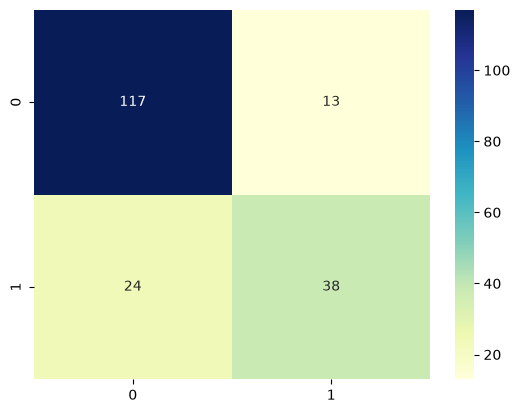

In [13]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
#sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='d')
#sns.heatmap(
#x.xaxis.set_label_position("top")


Confusion Matrix Evaluation Metrics
Let's evaluate the model using model evaluation metrics such as accuracy

In [14]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.8072916666666666


In [15]:
y_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0])

In [16]:
y_test

661    1
122    0
113    0
14     1
529    0
      ..
366    1
301    1
382    0
140    0
463    0
Name: label, Length: 192, dtype: int64

In [17]:
#y_test.columns=['TradeDate','TradeTime']

In [18]:
type(y_test)

pandas.Series

In [19]:
#y_test['newcol'] = y_pred
#print(y_test)

In [20]:
ytest_ypred= pd.DataFrame({'srno':y_test.index, 'y_test':y_test.values})

In [21]:
ytest_ypred['y_pred'] = y_pred
print(y_test)

661    1
122    0
113    0
14     1
529    0
      ..
366    1
301    1
382    0
140    0
463    0
Name: label, Length: 192, dtype: int64


In [22]:
ytest_ypred


,srno,y_test,y_pred
0,661,1,1
1,122,0,0
2,113,0,0
3,14,1,1
4,529,0,0
...,...,...,...
187,366,1,0
188,301,1,0
189,382,0,0
190,140,0,0


We want to check whether the model is overfit. A model that scores much better on the training data than on the test data has memorised the training data instead of learning a pattern.

Compare the accuracy on the training set with the accuracy on the test set:

In [23]:
# accuracy on the data the model was trained on, compared with the test data
y_train_pred = logreg.predict(X_train)
print("Training accuracy:", round(metrics.accuracy_score(y_train, y_train_pred), 3))
print("Test accuracy:    ", round(metrics.accuracy_score(y_test, y_pred), 3))

Training accuracy: 0.767
Test accuracy:     0.807


In [24]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
print("Precision:",metrics.precision_score(y_test, y_pred))
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.8072916666666666
Precision: 0.7450980392156863
Recall: 0.6129032258064516


In [25]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86       130
           1       0.75      0.61      0.67        62

    accuracy                           0.81       192
   macro avg       0.79      0.76      0.77       192
weighted avg       0.80      0.81      0.80       192



# Metrics

A classification rate of 80%, considered as good accuracy.





Precision:
Out of the total observations: how often is the model correct when it predicts as Diabetes?
Precision: Precision is about being precise, i.e., how accurate your model is. In other words, you can say, when a model makes a prediction, how often it is correct. In your prediction case, when your Logistic Regression model predicted patients are going to suffer from diabetes, that patients have diabetes about 75% of the time (precision = 0.745).

Recall (also called True Positive Rate or Sensitivity):
from all the actual instances of Diabetes, how often it correctly predicts Diabetes    
Recall: If there are Actual patients who have diabetes in the test set and your Logistic Regression model can identify it about 61% of the time (recall = 0.613).

# ROC CURVE - Receiver Operating Charasterict Curve

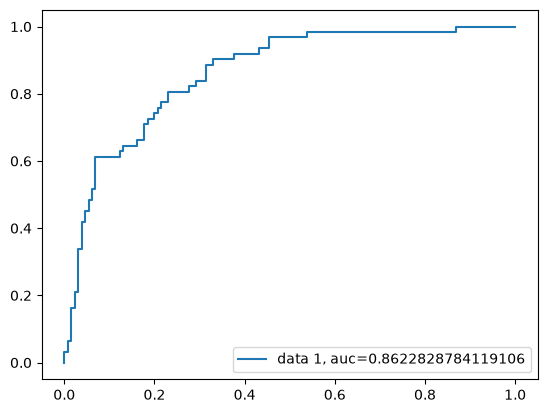

In [26]:


y_pred_proba = logreg.predict_proba(X_test)[::,1]


fpr, tpr,  th = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

In [27]:
y_pred_proba

array([0.95080354, 0.16134308, 0.1072554 , 0.62628808, 0.12734976,
       0.03784936, 0.74080336, 0.85227668, 0.45951681, 0.40515647,
       0.57140388, 0.96321781, 0.30844892, 0.23219158, 0.13820301,
       0.16060234, 0.83820361, 0.0272559 , 0.39410934, 0.26518988,
       0.62882329, 0.44323799, 0.24617479, 0.06918351, 0.05414411,
       0.33485508, 0.0447754 , 0.91158131, 0.09841938, 0.13940582,
       0.46192057, 0.24752931, 0.10172989, 0.47409192, 0.09172126,
       0.68047581, 0.41852468, 0.07584501, 0.30901935, 0.69184566,
       0.29840766, 0.24584911, 0.16367046, 0.7649922 , 0.75041687,
       0.00676815, 0.073289  , 0.18305201, 0.36328716, 0.29805565,
       0.38122714, 0.18476003, 0.88473901, 0.43246002, 0.15941989,
       0.0033185 , 0.05877421, 0.5709778 , 0.26567821, 0.06422669,
       0.68436978, 0.48186089, 0.09729955, 0.75449475, 0.63822371,
       0.89461946, 0.68607926, 0.13300336, 0.38058224, 0.11159809,
       0.12106882, 0.4150553 , 0.09539698, 0.95477151, 0.83943

In [28]:
th

array([       inf, 0.97086855, 0.96321781, 0.95477151, 0.94963928,
       0.91158131, 0.83820361, 0.83653375, 0.77351375, 0.77172376,
       0.71137178, 0.69184566, 0.67542197, 0.66327467, 0.63822371,
       0.63002894, 0.62628808, 0.62545974, 0.60174003, 0.59423302,
       0.51847531, 0.46192057, 0.46066958, 0.45951681, 0.44323799,
       0.43205723, 0.41852468, 0.40515647, 0.39515727, 0.39410934,
       0.38474918, 0.38058224, 0.37426463, 0.37189358, 0.36328716,
       0.36046687, 0.35285238, 0.35213817, 0.34050358, 0.30844892,
       0.30675909, 0.29840766, 0.29805565, 0.28027976, 0.26567821,
       0.26074762, 0.25166322, 0.24133826, 0.23925536, 0.20691591,
       0.20095533, 0.18476003, 0.18250362, 0.15767047, 0.15314575,
       0.06559223, 0.06422669, 0.0033185 ])

# Analysing the ROC Curve and AUC Score

AUC score for the case is 0.86. AUC score 1 represents perfect classifier, and 0.5 represents a worthless classifier.

# Improving the model

The model above is the baseline (default settings, raw data). Three things stood out:

1. **Convergence warning:** the optimiser ran out of iterations because the features are on very different scales (insulin goes up to 846, pedigree to 2.4).
2. **Zeros that are really missing values:** a glucose, blood pressure, skin thickness, insulin or BMI of 0 is not a real measurement.
3. **Recall is lower than precision:** the model misses patients who do have diabetes.

Below: check each issue, fix it, and compare with the baseline on the **same train/test split**.

## 1. Zeros that cannot be real measurements

In [29]:
cols_with_hidden_missing = ['glucose', 'bp', 'skin', 'insulin', 'bmi']
zero_counts = (pima[cols_with_hidden_missing] == 0).sum().to_frame('rows with 0')
zero_counts['share of 768'] = (zero_counts['rows with 0'] / len(pima)).round(3)
zero_counts

,rows with 0,share of 768
glucose,5,0.007
bp,35,0.046
skin,227,0.296
insulin,374,0.487
bmi,11,0.014


These zeros are missing values stored as 0. Left as they are, they pull the averages down and mislead the model. They are replaced with `NaN` and then filled with the **median of the training rows** (inside a pipeline, so no information from the test set leaks in).

## 2. Baseline to beat, and a better pipeline

In [30]:
# a model that always answers 'no diabetes'
print("Always predicting 'no diabetes' scores:", round((y_test == 0).mean(), 3), 'on the test set')

Always predicting 'no diabetes' scores: 0.677 on the test set


In [31]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# treat the impossible zeros as missing
# (skin thickness is not one of the model's seven features, so only the columns the model uses are cleaned)
cols_to_clean = [c for c in cols_with_hidden_missing if c in X.columns]
X_clean = X.copy()
X_clean[cols_to_clean] = X_clean[cols_to_clean].replace(0, np.nan)

# same split as before (same random_state), so the comparison is fair
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clean, y, test_size=0.25, random_state=0)

improved = Pipeline([
    ('impute', SimpleImputer(strategy='median')),   # median learned from the training rows only
    ('scale', StandardScaler()),                    # puts every feature on a similar scale
    ('model', LogisticRegression(max_iter=1000)),   # enough iterations to converge
])
improved.fit(Xc_train, yc_train)
y_pred_improved = improved.predict(Xc_test)
proba_improved = improved.predict_proba(Xc_test)[:, 1]
print('Same rows in the test set:', list(Xc_test.index) == list(X_test.index))

Same rows in the test set: True


In [32]:
def scores(y_true, pred, proba):
    return {'accuracy': metrics.accuracy_score(y_true, pred),
            'precision': metrics.precision_score(y_true, pred),
            'recall': metrics.recall_score(y_true, pred),
            'f1': metrics.f1_score(y_true, pred),
            'auc': metrics.roc_auc_score(y_true, proba)}

comparison = pd.DataFrame({
    'baseline (original)': scores(y_test, y_pred, y_pred_proba),
    'improved (impute + scale)': scores(yc_test, y_pred_improved, proba_improved),
}).T.round(3)
comparison

,accuracy,precision,recall,f1,auc
baseline (original),0.807,0.745,0.613,0.673,0.862
improved (impute + scale),0.792,0.729,0.565,0.636,0.859


In [33]:
print('Baseline confusion matrix:\n', metrics.confusion_matrix(y_test, y_pred))
print('Improved confusion matrix:\n', metrics.confusion_matrix(yc_test, y_pred_improved))

Baseline confusion matrix:
 [[117  13]
 [ 24  38]]
Improved confusion matrix:
 [[117  13]
 [ 27  35]]


## 3. ROC curves, baseline and improved

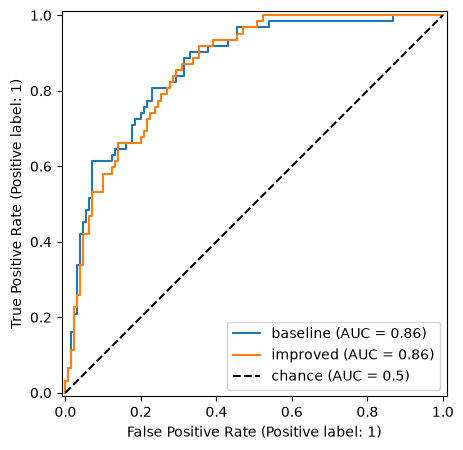

In [34]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_pred_proba, name='baseline', ax=ax)
RocCurveDisplay.from_predictions(yc_test, proba_improved, name='improved', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='chance (AUC = 0.5)')
ax.legend(loc='lower right')
plt.show()

## 4. Choosing the decision threshold

By default a patient is predicted 'diabetes' when the probability is at least 0.5. For screening, missing a patient who has diabetes (a false negative) is usually worse than a false alarm, so lowering the threshold can be sensible. The table shows the trade-off.

In [35]:
rows = []
for t in [0.5, 0.4, 0.35, 0.3, 0.25]:
    pred = (proba_improved >= t).astype(int)
    rows.append({'threshold': t,
                 'precision': metrics.precision_score(yc_test, pred),
                 'recall': metrics.recall_score(yc_test, pred),
                 'missed cases (false negatives)': int(((pred == 0) & (yc_test == 1)).sum()),
                 'false alarms (false positives)': int(((pred == 1) & (yc_test == 0)).sum())})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,missed cases (false negatives),false alarms (false positives)
0,0.50,0.729,0.565,27,13
1,0.40,0.672,0.661,21,20
2,0.35,0.614,0.694,19,27
3,0.30,0.588,0.806,12,35
4,0.25,0.557,0.871,8,43


## 5. Is it just luck of this one split? Cross-validation

A single 75/25 split can be lucky or unlucky. 5-fold stratified cross-validation trains and tests on five different splits and reports the average.

In [36]:
import warnings
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
baseline_model = Pipeline([('model', LogisticRegression())])        # original settings, raw data

table = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')                                  # the baseline repeats the convergence warning
    for name, model, data in [('baseline (original)', baseline_model, X), ('improved (impute + scale)', improved, X_clean)]:
        row = {}
        for metric in ['accuracy', 'recall', 'roc_auc']:
            s = cross_val_score(model, data, y, cv=cv, scoring=metric)
            row[metric] = f'{s.mean():.3f} +/- {s.std():.3f}'
        table[name] = row
pd.DataFrame(table).T

,accuracy,recall,roc_auc
baseline (original),0.776 +/- 0.024,0.582 +/- 0.046,0.834 +/- 0.028
improved (impute + scale),0.771 +/- 0.031,0.571 +/- 0.045,0.837 +/- 0.030


## Summary of the improvements

- **The baseline was already a sound model.** It scores 0.807 accuracy on the test split, against 0.677 for always answering "no diabetes", with an AUC of 0.86. It does **not** overfit: training accuracy is 0.767 and test accuracy is 0.807 (this particular test split happens to be a little easier).
- **Imputing the impossible zeros and scaling the features fixed the convergence warning, but did not improve the scores.** On this split the "improved" pipeline is slightly lower (accuracy 0.792 vs 0.807, recall 0.565 vs 0.613, AUC 0.859 vs 0.862). Across 5 cross-validation folds the two are equivalent (AUC 0.837 vs 0.834, recall 0.571 vs 0.582): the differences are much smaller than the fold-to-fold variation of about 0.03 to 0.05. Plain logistic regression is not very sensitive to these steps on this data, although cleaning the data and using a pipeline is still the more correct approach.
- **The single-split accuracy is slightly optimistic.** Cross-validated accuracy is about 0.77 to 0.78, not 0.81.
- **The decision threshold is what really changes the result.** Lowering it from 0.5 to 0.3 raises recall from 0.565 to 0.806 (missed cases drop from 27 to 12 out of 62), at the cost of 35 false alarms instead of 13 (precision falls to 0.588). Which point is best depends on how costly a missed case is compared with a false alarm.
- **Next steps:** try other models (random forest, gradient boosting), add feature interactions, and choose the threshold using the real cost of a missed case.
